# Text Price Prediction

For this project we have this taxi dataset we'll be predicting trip fares on various factors such as distance, time of day, traffic conditions, and more.

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("denkuznetz/taxi-price-prediction")

print("Path to dataset files:", path)

100%|██████████| 19.6k/19.6k [00:00<00:00, 13.7MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/denkuznetz/taxi-price-prediction/versions/1


In [5]:
cd /root/.cache/kagglehub/datasets/denkuznetz/taxi-price-prediction/versions/1

/root/.cache/kagglehub/datasets/denkuznetz/taxi-price-prediction/versions/1


In [6]:
ls

taxi_trip_pricing.csv


In [7]:
import pandas as pd

path = "/root/.cache/kagglehub/datasets/denkuznetz/taxi-price-prediction/versions/1/taxi_trip_pricing.csv"
df = pd.read_csv(path)
df.head()

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,Morning,Weekday,3.0,Low,Clear,3.56,0.80,0.32,53.82,36.2624
1,47.59,Afternoon,Weekday,1.0,High,Clear,NaN,0.62,0.43,40.57,NaN
2,36.87,Evening,Weekend,1.0,High,Clear,2.70,1.21,0.15,37.27,52.9032
3,30.33,Evening,Weekday,4.0,Low,NaN,3.48,0.51,0.15,116.81,36.4698
4,NaN,Evening,Weekday,3.0,High,Clear,2.93,0.63,0.32,22.64,15.6180


In [8]:
df.tail()

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
995,5.49,Afternoon,Weekend,4.0,Medium,Clear,2.39,0.62,0.49,58.39,34.4049
996,45.95,Night,Weekday,4.0,Medium,Clear,3.12,0.61,NaN,61.96,62.1295
997,7.70,Morning,Weekday,3.0,Low,Rain,2.08,1.78,NaN,54.18,33.1236
998,47.56,Morning,Weekday,1.0,Low,Clear,2.67,0.82,0.17,114.94,61.2090
999,22.85,Morning,Weekend,3.0,Medium,Clear,4.34,NaN,0.23,29.69,45.4437


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Trip_Distance_km       950 non-null    float64
 1   Time_of_Day            950 non-null    object 
 2   Day_of_Week            950 non-null    object 
 3   Passenger_Count        950 non-null    float64
 4   Traffic_Conditions     950 non-null    object 
 5   Weather                950 non-null    object 
 6   Base_Fare              950 non-null    float64
 7   Per_Km_Rate            950 non-null    float64
 8   Per_Minute_Rate        950 non-null    float64
 9   Trip_Duration_Minutes  950 non-null    float64
 10  Trip_Price             951 non-null    float64
dtypes: float64(7), object(4)
memory usage: 86.1+ KB


In [10]:
df.describe()

,Trip_Distance_km,Passenger_Count,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,951.000000
mean,27.070547,2.476842,3.502989,1.233316,0.292916,62.118116,56.874773
std,19.905300,1.102249,0.870162,0.429816,0.115592,32.154406,40.469791
min,1.230000,1.000000,2.010000,0.500000,0.100000,5.010000,6.126900
25%,12.632500,1.250000,2.730000,0.860000,0.190000,35.882500,33.742650
50%,25.830000,2.000000,3.520000,1.220000,0.290000,61.860000,50.074500
75%,38.405000,3.000000,4.260000,1.610000,0.390000,89.055000,69.099350
max,146.067047,4.000000,5.000000,2.000000,0.500000,119.840000,332.043689


In [11]:
df.isnull().sum()

,0
Trip_Distance_km,50
Time_of_Day,50
Day_of_Week,50
Passenger_Count,50
Traffic_Conditions,50
Weather,50
Base_Fare,50
Per_Km_Rate,50
Per_Minute_Rate,50
Trip_Duration_Minutes,50


In [12]:
df = df.dropna()

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["Passenger_Count"] = df["Passenger_Count"].astype(int)

<Axes: >

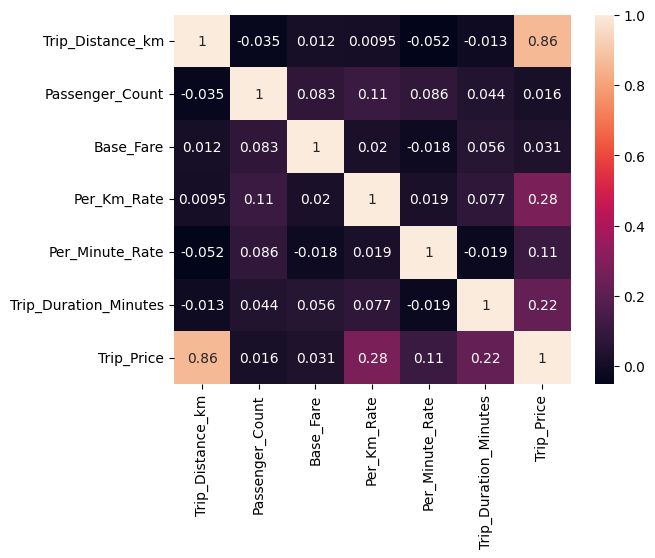

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(df.corr(numeric_only=True), annot = True)

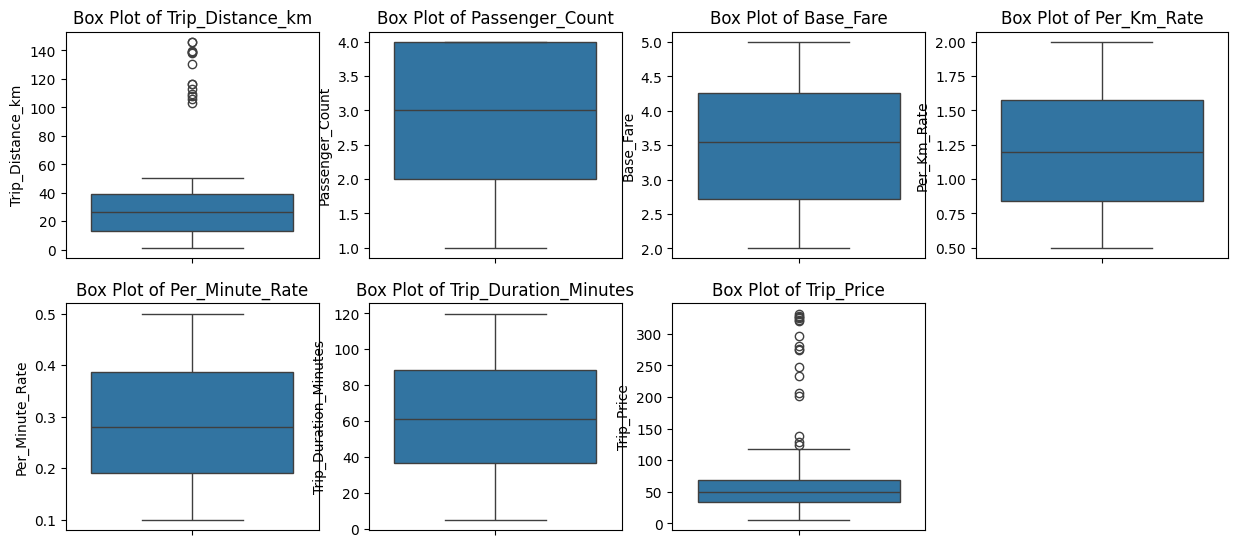

In [16]:
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_cols):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
plt.show()

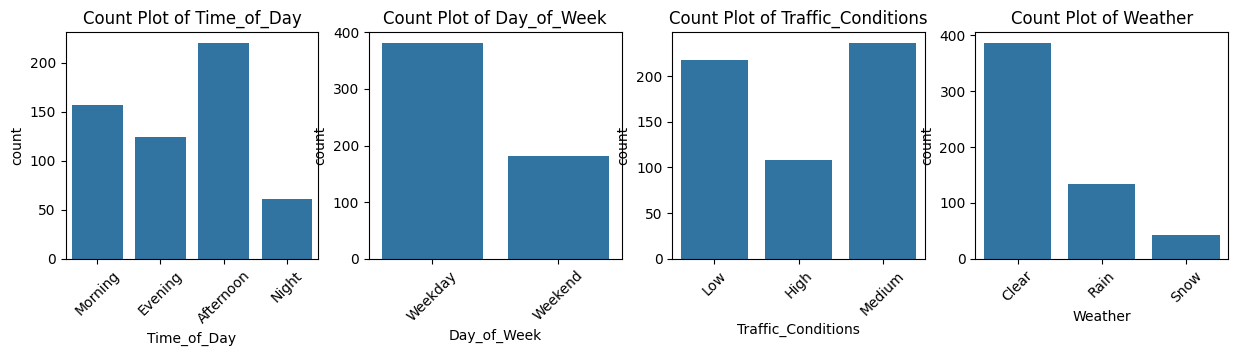

In [17]:
cat_cols = df.select_dtypes(include=['object']).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(cat_cols):
    plt.subplot(3, 4, i + 1)
    sns.countplot(x=df[col])
    plt.title(f'Count Plot of {col}')
    plt.xticks(rotation=45)
plt.show()

In [18]:
df = pd.get_dummies(df, drop_first=True)

In [19]:
df.head()

,Trip_Distance_km,Passenger_Count,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Day_of_Week_Weekend,Traffic_Conditions_Low,Traffic_Conditions_Medium,Weather_Rain,Weather_Snow
0,19.35,3,3.56,0.80,0.32,53.82,36.2624,False,True,False,False,True,False,False,False
2,36.87,1,2.70,1.21,0.15,37.27,52.9032,True,False,False,True,False,False,False,False
5,8.64,2,2.55,1.71,0.48,89.33,60.2028,False,False,False,True,False,True,False,False
12,41.79,3,4.60,1.77,0.11,86.95,88.1328,False,False,True,True,False,False,False,False
14,9.91,2,2.32,1.26,0.34,41.72,28.9914,True,False,False,False,False,False,False,False


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score


sc = StandardScaler()

x = df.drop("Trip_Price", axis=1)
y = df["Trip_Price"]

x = sc.fit_transform(x)
y = sc.fit_transform(y.values.reshape(-1, 1))

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "ElasticNet Regression": ElasticNet(),
    "SGD Regression": SGDRegressor()
}

results = []
for model_name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append({"Model": model_name, "Mean Squared Error": mse, "R-squared": r2})

results = pd.DataFrame(results)
results = results.sort_values(by="R-squared", ascending=False)
display(results)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,Model,Mean Squared Error,R-squared
4,SGD Regression,0.149914,0.884827
0,Linear Regression,0.150338,0.884502
1,Ridge Regression,0.150904,0.884067
3,ElasticNet Regression,0.894595,0.312721
2,Lasso Regression,1.304343,-0.002071


In [24]:
model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R-squared:", r2)


Mean Squared Error: 0.15033822025337118
R-squared: 0.884501603348416


In [27]:
fi = pd.DataFrame({"Feature": df.drop("Trip_Price", axis=1).columns, "Importance": model.coef_.flatten()})
fi

,Feature,Importance
0,Trip_Distance_km,0.840841
1,Passenger_Count,-0.009678
2,Base_Fare,-0.010094
3,Per_Km_Rate,0.248115
4,Per_Minute_Rate,0.158496
5,Trip_Duration_Minutes,0.218798
6,Time_of_Day_Evening,-0.018321
7,Time_of_Day_Morning,0.021097
8,Time_of_Day_Night,-0.004776
9,Day_of_Week_Weekend,0.019347


<BarContainer object of 14 artists>

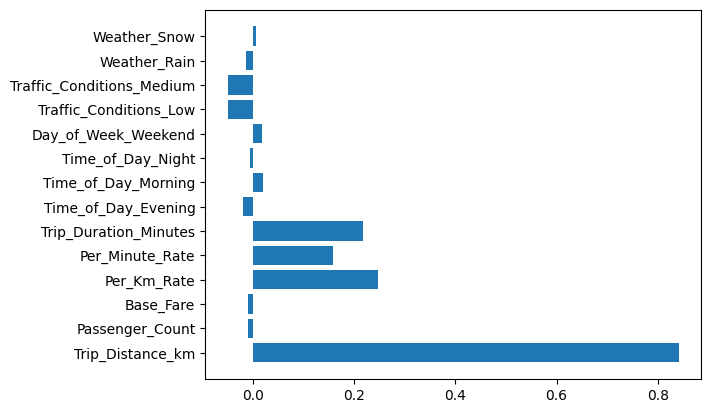

In [30]:
plt.barh(fi["Feature"], fi["Importance"])

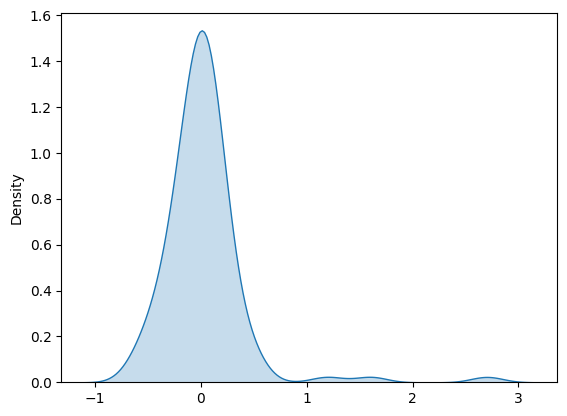

In [39]:
residuals = (y_test - y_pred).flatten()
sns.kdeplot(x = residuals, fill = True)
plt.show()

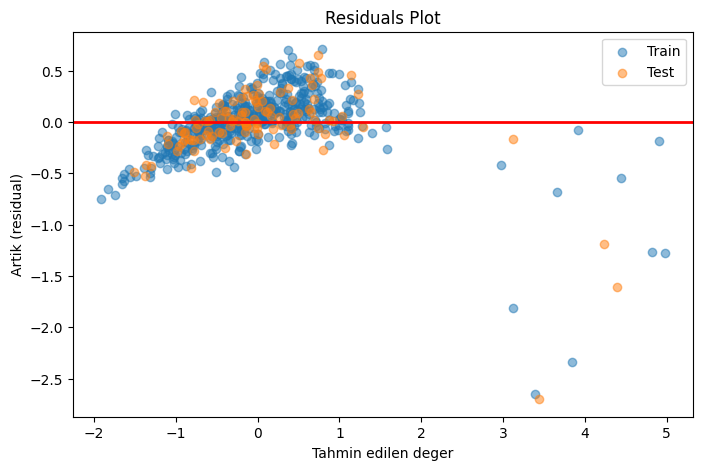

In [40]:
import numpy as np

ytr = np.ravel(y_train); yte = np.ravel(y_test)
ytr_pred = np.ravel(model.predict(x_train))
yte_pred = np.ravel(model.predict(x_test))

plt.figure(figsize=(8,5))
plt.scatter(ytr_pred, ytr_pred - ytr, alpha=.5, label='Train')
plt.scatter(yte_pred, yte_pred - yte, alpha=.5, label='Test')
plt.axhline(0, color='red', lw=2)
plt.xlabel('Tahmin edilen deger'); plt.ylabel('Artik (residual)')
plt.title('Residuals Plot'); plt.legend(); plt.show()

### Conclusion

I fetched the data, analyzed the categoricals and numericals data, turned the categorical ones to numbers and normalized numericals data with StandartScale and after wards tried some regression models and the best result was Linear Regression algorithm with 88 R2 score and 0.15033 Mean Squared Error